# Analyse des dialogues de Anakin dans Star Wars

# Introduction

Star Wars est une saga cinématographique emblématique de science-fiction créée par George Lucas, qui explore des thèmes universels comme la lutte entre le bien et le mal, le pouvoir, et la rédemption. Les épisodes I, II et III de la prélogie racontent l’ascension et la chute d’Anakin Skywalker, un Jedi puissant mais tourmenté, qui bascule progressivement vers le côté obscur pour devenir Dark Vador.

Dans le cadre de ce projet en traitement automatique du langage, l’objectif est d’étudier l’évolution psychologique et émotionnelle d’Anakin à travers ses dialogues dans les scripts de ces trois épisodes. À l’aide d’outils comme l’analyse des sentiments et l’extraction des thèmes récurrents, nous analyserons comment les choix linguistiques traduisent sa transformation.

Ce travail vise à démontrer le rôle des dialogues dans la construction narrative du basculement d’Anakin.

# 1. Importation des données

## 1.1 Importation des données par du scraping

Pour pouvoir analyser l'évolution de notre sujet vers le côté obscure, nous allons récupérer les scripts des la seconde trilogie de la saga. Pour se faire les scripts ont été scrapés sur des sites intrnets **anglais**.

In [13]:
import requests
from bs4 import BeautifulSoup
 
# Importation des scripts
def get_script(url, nom_fichier, SW):
    # Va chercher le contenu
    response = requests.get(url)
    soup = BeautifulSoup(response.text, "html.parser")

    # Trouve le contenu dans la bonne balise (balise de class unique sur le site donc facile à scraper)
    if SW == 1:
        script_text = soup.find_all("td", class_='scrtext')
    elif SW == 2:
        script_text = soup.find_all("pre")
    elif SW == 3:
        script_text = soup.find_all("td", class_='scrtext')

    # Écrit le contenu dans un fichier texte
    with open(f"Script/{nom_fichier}.txt", "w", encoding="utf-8") as file:
        for element in script_text:
            file.write(element.get_text() + "\n")

In [14]:
url1 = "https://imsdb.com/scripts/Star-Wars-The-Phantom-Menace.html"
url2 = "http://sellascript.com/Source/resources/screenplays/attackoftheclones.htm"
url3 = "https://imsdb.com/scripts/Star-Wars-Revenge-of-the-Sith.html"

get_script(url1, "StarWars1", 1)
get_script(url2, "StarWars2", 2)
get_script(url3, "StarWars3", 3)

Les données que nous venons de récupérer ne sont pas parfaites. En effet, il y a beaucoup d'erreurs dans le nom des personnages du genre *ANAKNN* ou *ANKIN* pour *ANAKIN*. Il faut donc prosséder à des modifications pour réussir à corriger toutes ces imperfections.

In [15]:
import os
import re
from difflib import SequenceMatcher

# Liste dynamique de noms rencontrés
noms_rencontres = []

# Fonction pour calculer la similarité entre deux chaînes
def similar(a, b):
    return SequenceMatcher(None, a, b).ratio()

# Fonction de correction dynamique des noms
def corriger_noms_dynamiques(script_path, seuil_similarite=0.8):
    global noms_rencontres

    # Charger le contenu du fichier
    with open(script_path, 'r', encoding='utf-8') as file:
        contenu = file.read()

    # Rechercher tous les mots en majuscules (souvent des noms de personnages)
    mots = re.findall(r'\b[A-Z]+\b', contenu)

    # Parcourir chaque mot trouvé
    for mot in mots:
        trouve_similaire = False
        for nom_existant in noms_rencontres:
            # Vérifier la similarité avec les noms déjà rencontrés
            if similar(mot, nom_existant) >= seuil_similarite:
                contenu = re.sub(rf'\b{mot}\b', nom_existant, contenu)
                trouve_similaire = True
                break
        
        # Si aucun nom similaire n'a été trouvé, ajouter ce nom à la liste
        if not trouve_similaire:
            noms_rencontres.append(mot)

    # Sauvegarder le contenu corrigé
    with open(script_path.replace('.txt', '_corrige.txt'), 'w', encoding='utf-8') as file:
        file.write(contenu)

# Parcourir les scripts dans le dossier Script
dossier_scripts = "Script"
for fichier in os.listdir(dossier_scripts):
    if fichier.endswith(".txt"):
        script_path = os.path.join(dossier_scripts, fichier)
        corriger_noms_dynamiques(script_path)



## 1.2 Dictionnaire des personages

Une fois les données propres placées dans de nouveaux fichiers, nous allons trier. Pour se faire trois dictionnaires vont être créé :

- gentils : contenant tous les dialogues des personnages bienveillant de l'univers

- méchant : tous les personnages du côté obscur

- Anakin : toues les répliques de Anakin et Darth Vador

Mais avant cela il faut commencer par assimiler chaque répliques à son personnage.

In [16]:
import re

def dico_StarWars(fichier, SW):
# Lire le script
    with open(f"Script/{fichier}_corrige.txt", "r", encoding="utf-8") as f:
        script_text = f.read()

    # Mettre tout le contenu sur la même ligne
    script_text = script_text.replace("\n", " ")

    # Correction des mots collés (insère un espace entre les minuscules et majuscules, si nécessaire)
    script_text = re.sub(r"([a-z])([A-Z])", r"\1 \2", script_text)

    # Suppression des caractères spéciaux sauf les espaces et les deux-points
    script_text = re.sub(r"[^\w\s:]", "", script_text)

    # Trouver le pattern (Au moins deux majuscules à la suite puis ' : ') pour séparer les personnages de leurs réppliques
    if SW == 1:
        pattern = re.compile(r"[A-Z]{2,} :")
    else:
        pattern = re.compile(r"[A-Z]{2,}:")

    # Dans un nouveau dictionnaire en clé les noms des personnages et en valeur leur répliques
    dialogues = {}
    for match in pattern.finditer(script_text):
        # Trouver le nom du personnage
        if SW == 1:
            personnage = match.group().split(" :")[0]
        else:
            personnage = match.group().split(":")[0]
        
        # Trouver la réplique du personnage
        dialogue = script_text[match.end(): script_text.find(":", match.end())]
        
        # Supprimer tout ce qui suit une séquence de deux espaces dans le dialogue
        dialogue = re.split(r"\s{2,}", dialogue)[0]
        
        # Ajouter le personnage et sa réplique dans le dictionnaire
        if personnage not in dialogues:
            dialogues[personnage] = [dialogue.strip()]
        else:
            dialogues[personnage].append(dialogue.strip())
    
    # Mise en minuscule de tous les caractères 
    for personnage in dialogues:
        dialogues[personnage] = [dialogue.lower() for dialogue in dialogues[personnage]]
        
    return dialogues

# Exemple d'affichage des premiers dialogues de personnages
SW1= dico_StarWars("StarWars1", 1)
print(SW1['ANAKIN'][:2])

SW2= dico_StarWars("StarWars2", 2)
print(SW2['OBIWAN'][:2])

SW3= dico_StarWars("StarWars3", 3)
print(SW3['PADME'][:2])

On constate que nous avons bien réussià récupérer les répliques dans des dictionnaires, avec en clé les noms des personnages et en valeur une liste de chacun des dialogues.

# 2. Analyse des scripts

## 2.1 Préparation des groupes

Pour faire l'analye de Anakin au fur et à mesur des Star Wars nous allons tout d'abord analyser les discours des gentils et des méchants. Voir les différentes similarités pour ensuite essayer de prédire le moment où Anakin passe du côté obscur. Pour visualiser les thèmes qui prédominent chaque groupe, nous allons réaliser des nuages de mots

In [17]:
# Grâce à ChatGPT on obtient deux listes contenants les gentils et les méchants de la saga
# Dans lesquels on a bien évidement enlevé ANAKIN et VADER (spoil)
gentils = [
    'CARD', 'QUIGON', 'CAPTAIN', 'OBIWAN', 'AMIDALA', 'PANAKA', 
    'BIBBLE', 'JAR', 'TARPALS', 'NASS', 'PADME', 'OLIE', 'SHMI', 
    'THREEPIO', 'KITSTER', 'WALD', 'AMEE', 'SEEK', 'FODEBEED', 'FANTA', 
    'ODY', 'BEED', 'WINDU', 'KIADI', 'YODA', 'RABE', 'ORGANA', 'ASSEMBLY', 'CEEL', 
    'SABE', 'THEED', 'TYPHO', 'AAK', 'DARSANA', 'TAA', 'KIADIMUNDI', 'JETTSTER', 
    'NU', 'CHILDEREN', 'JACK', 'MAY', 'JAMILLIA', 'POOJA', 'SOLA', 'JOBAL', 'RUWEE', 
    'WE', 'SUB', 'OWEN', 'BERU', 'CLIEGG', 'SENATOR', 'PO', 'TROOPER', 'YOUNGLINGS', 
    'ANTILLES', 'BAIL', 'AAYLA', 'BLY', 'KOON', 'MOTHMA', 'BREEMU', 'EEKWAY', 'MEDON'
]

mechants = [
    'NUTE', 'DOFINE', 'RUNE', 'HOW', 'SIDIOUS', 'DROID', 'GUARDS', 'WATTO', 'VENDOR', 
    'SEBULBA', 'JIRA', 'MAUL', 'GUIGON', 'GREEDO', 'PILOT', 'VALORUM', 'DOD', 'MORE', 
    'AMEDDA', 'LOOKOUT', 'TWO', 'WESELL', 'FETT', 'SLEAZEBAGGANO', 'ELAN', 'ZAM', 
    'DOOKU', 'GUNRAY', 'POGGLE', 'SARGEANT', 'MAIN', 'HILL', 'TAMBOR', 'FAC', 'HAAKO', 
    'COMMAND', 'SIDIOUS', 'GRIEVOUS', 'BODYGUARDS', 'NDU', 'DIOUS', 'MENACE', 'ADIMUNDI', 
    'MOTEE', 'WRANGLERS', 'BACARA', 'THIRD', 'GON', 'PALPATINE', 'JABBA'
]

# Listes pour stocker les dialogues des gentils, des méchants, et d'Anakin/Vader
gentils_dialogues = []
mechants_dialogues = []
anakin_dialogues = []

for film in [SW1, SW2, SW3]:
    for personnage, dialogues in film.items():
        if personnage in gentils:
            gentils_dialogues.extend(dialogues)
        elif personnage in mechants:
            mechants_dialogues.extend(dialogues)
        elif personnage in ['ANAKIN', 'VADER']:
            anakin_dialogues.extend(dialogues)

print(f"Nombre de dialogues des gentils: {len(gentils_dialogues)}\nNombre de dialogues des méchants: {len(mechants_dialogues)}\nNombre de dialogues d'Anakin/Vader: {len(anakin_dialogues)}")

Nombre de dialogues des gentils: 1684
Nombre de dialogues des méchants: 598
Nombre de dialogues d'Anakin/Vader: 713


On remarque que la répartition des dialogues entre les gentils et les méchants n'est pas du tout équitable. Il y a presque trois fois plus de dialogues de gentils que de méchants. Il faudra donc faire attention à ça pendant la suite de notre analyse.

## 2.2 Tokenisation et comptage des mots

La tokenisation sert à diviser un texte en unités significatives, comme des mots ou des phrases, pour faciliter son analyse et traitement automatique.

In [18]:
import spacy

# Charger le modèle de langue anglaise de spacy
nlp_en = spacy.load("en_core_web_sm")

def toke(texte):
    l_texte = ' '.join(texte)   # Joindre tous les dialogues en une seule chaîne de caractères
    doc_texte = nlp_en(l_texte) # Traiter le texte avec spacy
    # Extraire les mots qui ne sont pas des stop words ou de la ponctuation
    words_texte = [token.text for token in doc_texte if not token.is_stop and not token.is_punct]
    return [doc_texte, words_texte]

toke_gentils = toke(gentils_dialogues)
toke_mechants = toke(mechants_dialogues)
toke_anakin = toke(anakin_dialogues)

# print(toke_anakin)

Une fois les données tokhenisées, on compte le nombre de fois que les mots sont présents dans chacuns des dictionnaires pour voir quels mots ressortent le plus souvent.

In [ ]:
# Création des dictionnairesdes comptages des mots
def dico_comptage_mots(words_texte):
    dico_comptage = {}
    for word in words_texte:
        if word in dico_comptage:
            dico_comptage[word] += 1
        else:
            dico_comptage[word] = 1
    # Tri des mots par ordre décroissant de fréquence
    dico_comptage = dict(sorted(dico_comptage.items(), key=lambda item: item[1], reverse=True))
    return dico_comptage

d_gentils = dico_comptage_mots(toke_gentils[1])
d_mechants = dico_comptage_mots(toke_mechants[1])
d_anakin = dico_comptage_mots(toke_anakin[1])

# Suppression des noms de personnages qui apparaissent dans les valeurs
for mot in gentils:
    d_gentils.pop(mot, None)

for mot in mechants:
    d_mechants.pop(mot, None)

for mot in ['ANAKIN', 'VADER']:
    d_anakin.pop(mot, None)

# Les 5 premiers éléments du dictionnaire de Anakin
print(list(d_anakin.items())[:5])


[('nt', 136), ('m', 85), ('master', 80), ('s', 49), ('know', 45)]


Après analyse des dictionnaires on remarques que certains mots doivent être supprimé manuellement. On va aussi supprimer tous les noms des personnages qui sont dans les dialogues pour pouvoir faire une analys eplus claire, sans étudier les relations entre ces derniers.

In [22]:
mots_a_supprimer = ['nt', 's', 've', 'm', 'jar', 'artoo'] + [mot.lower() for mot in gentils] + [mot.lower() for mot in mechants] + ['anakin', 'vader']
def suppr_mots_inutiles(dico, mots_a_supprimer):
    return {mot: valeur for mot, valeur in dico.items() if mot not in mots_a_supprimer}

d_gentils = suppr_mots_inutiles(d_gentils, mots_a_supprimer)
d_mechants = suppr_mots_inutiles(d_mechants, mots_a_supprimer)
d_anakin = suppr_mots_inutiles(d_anakin, mots_a_supprimer)


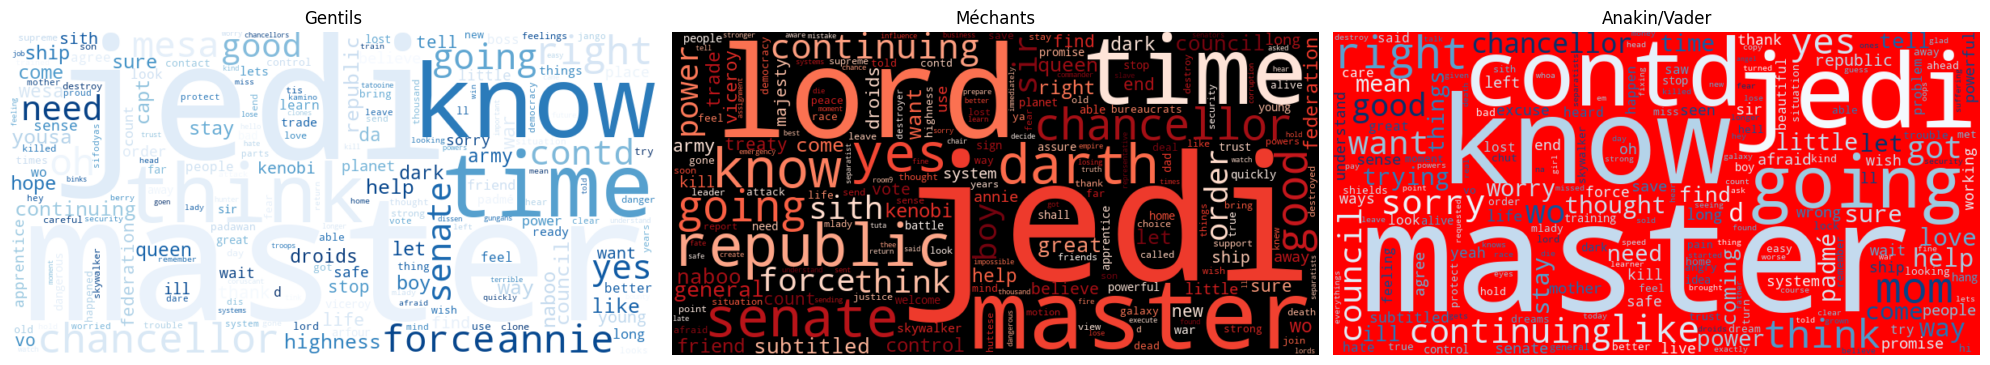

In [23]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Génération des nuages de mots
wordcloud_gentil = WordCloud(width=800, height=400, background_color='white', colormap='Blues').generate_from_frequencies(d_gentils)
wordcloud_mechant = WordCloud(width=800, height=400, background_color='black', colormap='Reds_r').generate_from_frequencies(d_mechants)
wordcloud_anakin = WordCloud(width=800, height=400, background_color='red', colormap ='Blues').generate_from_frequencies(d_anakin)

# Configuration de la figure avec 3 sous-graphes côte à côte
fig, axs = plt.subplots(1, 3, figsize=(20, 5))

# Affichage du nuage de mots pour les gentils
axs[0].imshow(wordcloud_gentil, interpolation='bilinear')
axs[0].axis('off')
axs[0].set_title("Gentils")

# Affichage du nuage de mots pour les méchants
axs[1].imshow(wordcloud_mechant, interpolation='bilinear')
axs[1].axis('off')
axs[1].set_title("Méchants")

# Affichage du nuage de mots pour Anakin/Vader
axs[2].imshow(wordcloud_anakin, interpolation='bilinear')
axs[2].axis('off')
axs[2].set_title("Anakin/Vader")

# Afficher la figure complète
plt.tight_layout()
plt.show()

Dans le nuage de mots des **“Gentils”**, les mots dominants sont “know”, “master”, “jedi”, et “think”. Ces termes suggèrent un discours centré sur la sagesse, la connaissance, et l’apprentissage, ce qui correspond bien aux valeurs des Jedi. Les mots “council” et “senate” montrent aussi l’importance des institutions et de la coopération dans leur discours. Cette orientation vers le savoir et la réflexion est typique des Jedi, qui privilégient la patience, l’enseignement, et la diplomatie, en ligne avec les valeurs du côté lumineux de la Force.

Le nuage de mots des **“Méchants”** est dominé par “lord”, “jedi”, “time”, et “power”. Ces termes illustrent bien leur obsession pour la domination, la maîtrise de la Force pour le pouvoir, et l’ambition. On remarque aussi des mots comme “senate” et “republic”, mais ils sont probablement utilisés ici dans un contexte plus critique ou manipulateur, puisqu’ils cherchent souvent à subvertir ces institutions pour leurs propres fins.

Dans le nuage de mots **d’“Anakin/Vader”**, les mots les plus fréquents sont “jedi”, “master”, “know”, “think”, et “mom”. La forte présence de mots liés aux Jedi et aux maîtres (“master”) montre son attachement initial à l’ordre Jedi, mais aussi son conflit constant. L’apparition de “mom” et “padme” reflète son attachement personnel et émotionnel, montrant qu’Anakin est tiraillé entre ses relations personnelles et ses devoirs de Jedi. Ces préoccupations émotionnelles contribuent à son basculement vers le côté obscur, car ses peurs et sa colère prennent progressivement le dessus.

# 3. Analyse de Anakin

## 3.1 Création d'un modèle avec `sklearn`

In [24]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

# Préparer les données d'entraînement
X = gentils_dialogues + mechants_dialogues
y = ['gentil'] * len(gentils_dialogues) + ['mechant'] * len(mechants_dialogues)

# Diviser les données en ensembles d'entraînement et de test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Créer un pipeline avec TF-IDF et SVM
model = make_pipeline(TfidfVectorizer(), SVC(kernel='linear'))

# Entraîner le modèle
model.fit(X_train, y_train)

# Évaluer le modèle
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))

# Classifier les dialogues d'Anakin
anakin_classifications = model.predict(anakin_dialogues)

# Afficher les résultats
l_classification = list()
for dialogue, classification in zip(anakin_dialogues, anakin_classifications):
    # print(f"Dialogue: {dialogue}\nClassification: {classification}\n")
    l_classification.append(classification)

              precision    recall  f1-score   support

      gentil       0.79      0.96      0.86       343
     mechant       0.62      0.22      0.32       114

    accuracy                           0.77       457
   macro avg       0.71      0.59      0.59       457
weighted avg       0.75      0.77      0.73       457



Les résultats montrent que le modèle reconnaît bien les dialogues des “gentils” d’Anakin (77% de précision globale), mais il a du mal à identifier ceux liés au “côté obscur” (seulement 32% en f1-score pour les “méchants”). Cela s’explique par le déséquilibre dans les données et par le fait qu’Anakin utilise parfois des mots ambigus ou conflictuels. Par exemple, ses dialogues affectueux envers Padmé sont classés “gentils”, tandis que ceux adressés à “my lord” sont classés “méchants”.

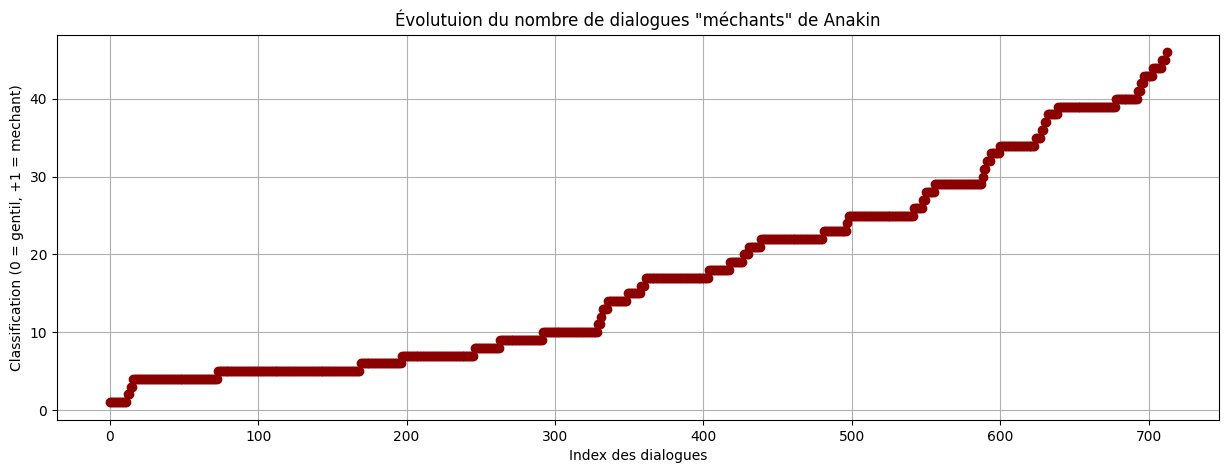

In [26]:
import matplotlib.pyplot as plt

# Convertir les classifications en valeurs numériques
def graph_evolution(l_classif):
    classification_numerique = list()
    compteur = 0
    for i in [1 if c == 'mechant' else 0 for c in l_classif]:
        if i>0:
            compteur +=1
        classification_numerique.append(compteur)


    # Créer le graphique
    plt.figure(figsize=(15, 5))
    plt.plot(classification_numerique, marker='o', color='darkred')
    plt.xlabel('Index des dialogues')
    plt.ylabel('Classification (0 = gentil, +1 = mechant)')
    plt.title('Évolutuion du nombre de dialogues \"méchants\" de Anakin')
    plt.grid(True)
    plt.show()

graph_evolution(l_classification)

In [ ]:
# Interprétation des résultats
gentil_anakin = sum(1 for c in anakin_classifications if c == 'gentil')
mechant_anakin = sum(1 for c in anakin_classifications if c == 'mechant')
print(f"Nombre de dialogues classés comme gentils: {gentil_anakin}\nNombre de dialogues classés comme méchants: {mechant_anakin}")

Nombre de dialogues classés comme gentils: 667
Nombre de dialogues classés comme méchants: 46


Le graphique illustre bien l’évolution d’Anakin de Jedi prometteur vers une figure de plus en plus sombre. La courbe montre une transformation progressive, marquée par des moments de conflit intérieur, jusqu’à un basculement final plus marqué. On remarque que Anakin a prononcé bien plus de dialogues du coté des gentils que de celui des méchants. Mais on constate que quand il y a un dialogue détecté "méchants" les suivantes le sont aussi.

## 3.2 Études des sentiments de Anakin

Les pensées et les sentiments sont le fond du passaage du côté obscure de Anakin. Nous pouvons étudier les sentiments de chacune de ces phrases et faire une représentation graphique de ces dernières pour voir si au fur et à mesure de la trilogique, sa déscente s'accélère.

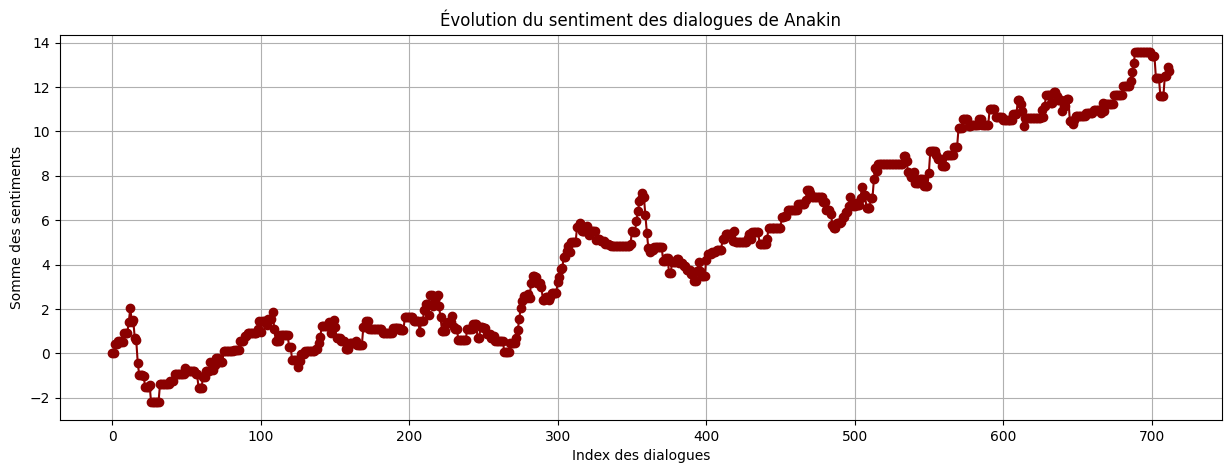

In [ ]:
from textblob import TextBlob

# Analyser le sentiment des dialogues d'Anakin
sentiments_anakin = [TextBlob(dialogue).sentiment.polarity for dialogue in anakin_dialogues]

l_sentiments = list()

# Afficher les résultats dans l'ordre original
for dialogue, sentiment in zip(anakin_dialogues, sentiments_anakin):
    l_sentiments.append(sentiment)
    # print(f"Dialogue: {dialogue}\nSentiment: {sentiment}\n")

def graph_evolution_sentiment(l_sentiment):
    compteur = 0
    classification_numerique = list()
    for i in l_sentiment:
        compteur += i
        classification_numerique.append(compteur)

    # Créer le graphique
    plt.figure(figsize=(15, 5))
    plt.plot(classification_numerique, marker='o', color='darkred')
    plt.xlabel('Index des dialogues')
    plt.ylabel('Somme des sentiments')
    plt.title('Évolution du sentiment des dialogues de Anakin')
    plt.grid(True)
    plt.show()

graph_evolution_sentiment(l_sentiments)


Le graphique ci-dessus montre l'évolution des sentiments de Anakin. Pour se faire chaque phrase du script de ce personnage a été anaylsé et un score lui a été attribué. le score est compris entre $[-1,1]$, plus le score est élévé alors plus le sentiment qui est exprimé dans la phrase est positif. En revanche si le score est plus proche de $-1$ alors le sentiment qui est évoqué est un sentiment négatif. Si le score est nulle il n'y a pas de sentiments particulié dans la phrase. 

L'allure générale de la courbe est croissante donc le sentiment générale qui envahit Anakin est quand même quelque chose de positif. On peut remarquer un pique au niveau du 360e dialogue, cela correspond surement au moments de romance qu'il y a entre Anakin.

# Conclusion

Ce projet a permis d’explorer la transformation psychologique et émotionnelle d’Anakin Skywalker dans les épisodes I, II et III de Star Wars à travers l’analyse des dialogues de ses scripts. En mobilisant différentes méthodes de traitement automatique du langage, telles que l’analyse des sentiments, l’extraction des thèmes récurrents et l’étude des interactions linguistiques, nous avons mis en évidence des tendances marquantes qui illustrent son passage progressif vers le côté obscur.

Les résultats obtenus montrent une évolution significative dans le ton et les émotions exprimées par Anakin : d’un langage chargé de naïveté et d’espoir, il adopte progressivement des expressions marquées par la peur, la colère et la haine.

Enfin, ce projet a non seulement permis de démontrer l’applicabilité des outils de traitement du language dans un contexte culturel, mais a également ouvert des perspectives sur l’analyse automatique des personnages de Star Wars. Ces techniques pourraient être étendues à d’autres domaines, comme l’étude des relations entre personnages ou la modélisation des arcs narratifs à grande échelle.